# SMS Spam Classification using SVM (extended version)

**Goal:** given a text message, decide if it is **spam** (junk / scam) or **ham** (a normal message).

**How it works, in one paragraph:** computers can't read words, so we turn every message into numbers (**TF-IDF**: how important each word is in a message). Then a **Support Vector Machine (SVM)** learns a boundary that separates the spam numbers from the ham numbers. New messages are put through the same steps and the SVM says which side they fall on.

**Dataset:** [SMS Spam Collection (Kaggle / UCI)](https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset) - 5,572 messages, labelled `ham` or `spam`.

### What is in this notebook
| Part | Sections |
|---|---|
| Lab baseline (from ma'am's notebook) | load data, EDA, preprocessing, split, SVM, tuning, cross-validation, prediction function |
| Added earlier | confusion matrix, ROC curve, model comparison, error analysis, saving the model |
| **New in this version** | automatic dataset download (runs anywhere), PR curve, **better features (char + word n-grams)**, repeated cross-validation, an experiment that *didn't* help (handcrafted features), **threshold tuning**, **which words make a message spam**, error analysis on the original text, confidence score in the predictor |

### How to run
* **Google Colab:** open the notebook, then *Runtime > Run all*. The dataset downloads by itself.
* **Your computer:** `pip install -r requirements.txt`, then `jupyter notebook` and *Run all*.

## 1. Setup

In [1]:
import importlib.util, subprocess, sys
_pkgs = {"wordcloud":"wordcloud","nltk":"nltk","scikit-learn":"sklearn","seaborn":"seaborn",
         "pandas":"pandas","matplotlib":"matplotlib","joblib":"joblib"}
_missing = [p for p, m in _pkgs.items() if importlib.util.find_spec(m) is None]
if _missing:
    subprocess.check_call([sys.executable, "-m", "pip", "-q", "install", *_missing])

In [2]:
import os, re, string, warnings, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import nltk

from sklearn.model_selection import (train_test_split, GridSearchCV, cross_val_score,
                                     cross_val_predict, cross_validate, RepeatedStratifiedKFold)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, precision_score, recall_score, f1_score,
                             roc_curve, auc, precision_recall_curve, average_precision_score)
from scipy.sparse import csr_matrix

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
RANDOM_STATE = 42
os.makedirs("images", exist_ok=True)
os.makedirs("models", exist_ok=True)

In [3]:
# NLTK word lists: stopwords ("the", "is", "and"...) and WordNet (for lemmatizing).
# If the download is blocked we fall back so the notebook still runs.
try:
    for pkg, path in [("stopwords", "corpora/stopwords"), ("wordnet", "corpora/wordnet")]:
        try:
            nltk.data.find(path)
        except LookupError:
            nltk.download(pkg, quiet=True)
    from nltk.corpus import stopwords
    from nltk.stem import WordNetLemmatizer
    stop_words = set(stopwords.words("english"))
    lemm = WordNetLemmatizer(); lemm.lemmatize("test")
    print("NLTK data ready.")
except Exception as e:
    from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
    stop_words = set(ENGLISH_STOP_WORDS)
    class _NoLemm:
        def lemmatize(self, w): return w
    lemm = _NoLemm()
    print("NLTK data unavailable -> using fallback stopwords, no lemmatizer:", type(e).__name__)

NLTK data ready.


## 2. Load the dataset
The file `spam.csv` is downloaded automatically if it isn't next to the notebook. (On Colab, if the download fails, a file-upload box appears - upload `spam.csv` from Kaggle.)

In [4]:
DATA_URL = "https://raw.githubusercontent.com/mohitgupta-omg/Kaggle-SMS-Spam-Collection-Dataset-/master/spam.csv"

if not os.path.exists("spam.csv"):
    try:
        urllib.request.urlretrieve(DATA_URL, "spam.csv")
        print("Downloaded spam.csv")
    except Exception as e:
        try:
            from google.colab import files
            print("Download failed, please upload spam.csv:")
            files.upload()
        except ImportError:
            raise FileNotFoundError("Put spam.csv (from Kaggle) in this folder and re-run.") from e

df = pd.read_csv("spam.csv", encoding="latin-1")   # latin-1 because the file has special characters
df = df[["v1", "v2"]]                               # keep only label + text columns
df.columns = ["label", "message"]
df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


## 3. Quick data checks

In [5]:
print(df.shape)
print(df.info())
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())
print(df["label"].value_counts())

(5572, 2)
<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   label    5572 non-null   str  
 1   message  5572 non-null   str  
dtypes: str(2)
memory usage: 541.4 KB
None
label      0
message    0
dtype: int64
Duplicates: 403
label
ham     4825
spam     747
Name: count, dtype: int64


**What we learn:** about 13% of messages are spam, so the data is **imbalanced**. That means plain *accuracy* can fool us (a model that says "ham" every time would already score ~87%). This is why we also look at **precision, recall and F1** for the spam class.

There are also ~400 **duplicate** messages. If the same message sat in both train and test, the model would be "tested" on something it already saw, so we remove duplicates *before* splitting.

## 4. Exploratory Data Analysis

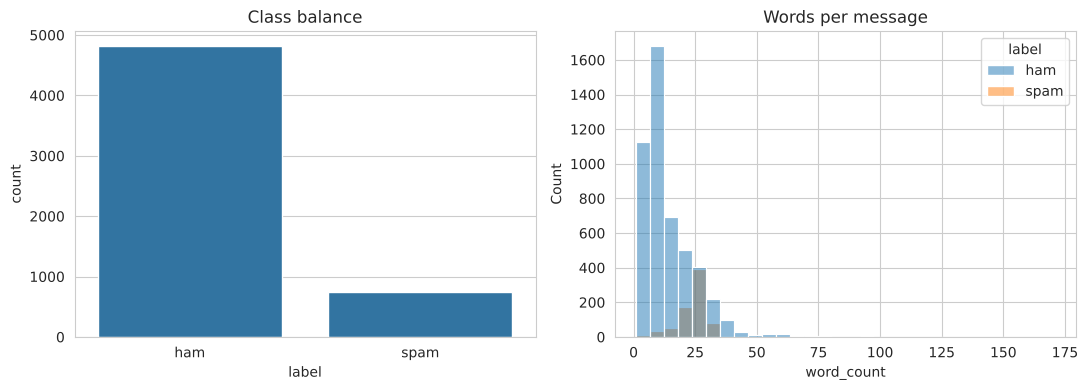

       char_count  word_count
label                        
ham          71.0        14.2
spam        138.9        23.9


In [6]:
df["char_count"] = df["message"].str.len()
df["word_count"] = df["message"].str.split().str.len()

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(data=df, x="label", ax=ax[0]); ax[0].set_title("Class balance")
sns.histplot(data=df, x="word_count", hue="label", bins=30, ax=ax[1]); ax[1].set_title("Words per message")
plt.tight_layout(); plt.savefig("images/eda_class_and_length.png", dpi=130); plt.show()

print(df.groupby("label")[["char_count", "word_count"]].mean().round(1))

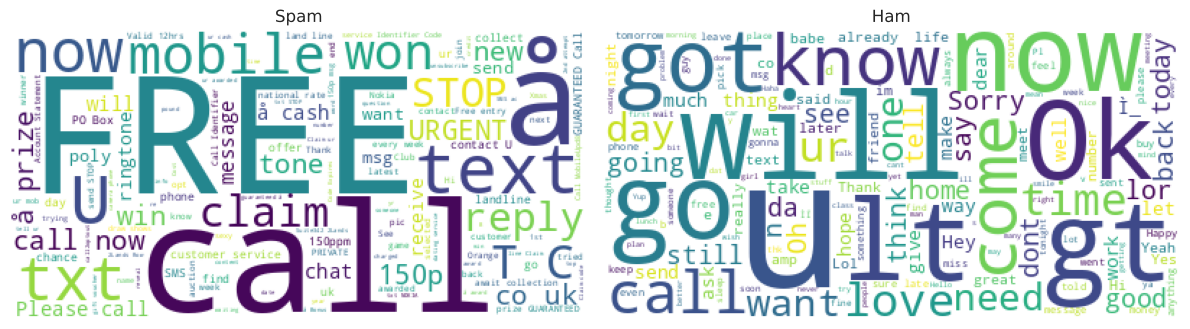

In [7]:
spam_text = " ".join(df[df.label == "spam"].message)
ham_text  = " ".join(df[df.label == "ham"].message)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1); plt.imshow(WordCloud(background_color="white").generate(spam_text)); plt.axis("off"); plt.title("Spam")
plt.subplot(1, 2, 2); plt.imshow(WordCloud(background_color="white").generate(ham_text));  plt.axis("off"); plt.title("Ham")
plt.tight_layout(); plt.savefig("images/wordclouds.png", dpi=130); plt.show()

**Observation:** spam messages are noticeably *longer* (more words/characters) and full of words like *free, call, txt, claim, prize, urgent*. Ham looks like everyday chat.

## 5. Preprocessing
Cleaning turns messy text into simple tokens: lowercase, remove links / emails / numbers / punctuation, drop stopwords, and **lemmatize** (reduce words to their base form, e.g. *messages -> message*).

In [8]:
def clean_text(text):
    text = text.lower()                                   # lowercase
    text = re.sub(r"http\S+|www\S+", " ", text)           # remove URLs
    text = re.sub(r"\S+@\S+", " ", text)                  # remove emails
    text = re.sub(r"\d+", " ", text)                       # remove numbers
    text = text.translate(str.maketrans("", "", string.punctuation))  # remove punctuation
    tokens = [lemm.lemmatize(w) for w in text.split() if w not in stop_words]
    return " ".join(tokens)

df = df.drop_duplicates().reset_index(drop=True)          # remove duplicates BEFORE splitting
df["clean_message"] = df["message"].apply(clean_text)
df["label"] = df["label"].map({"ham": 0, "spam": 1})      # ham -> 0, spam -> 1
print("After removing duplicates:", df.shape, "| spam share:", round(df.label.mean(), 3))
df[["message", "clean_message", "label"]].head()

After removing duplicates: (5169, 5) | spam share: 0.126


,message,clean_message,label
0,"Go until jurong point, crazy.. Available only ...",go jurong point crazy available bugis n great ...,0
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni,0
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry wkly comp win fa cup final tkts st ...,1
3,U dun say so early hor... U c already then say...,u dun say early hor u c already say,0
4,"Nah I don't think he goes to usf, he lives aro...",nah dont think go usf life around though,0


## 6. Train / test split
80% for training, 20% kept aside for the final exam. `stratify` keeps the spam share equal in both parts. We keep the **original text** and the **cleaned text** side by side (the improved model in section 11 uses the original text).

In [9]:
train_df, test_df = train_test_split(df, test_size=0.20, random_state=RANDOM_STATE, stratify=df["label"])

X_train, X_test = train_df["clean_message"], test_df["clean_message"]       # cleaned text (baseline)
Xr_train, Xr_test = train_df["message"], test_df["message"]                  # original text (improved model)
y_train, y_test = train_df["label"], test_df["label"]
print(X_train.shape, X_test.shape, "| spam in test:", int(y_test.sum()))

(4135,) (1034,) | spam in test: 131


## 7. Baseline SVM (the lab model)
**Pipeline** = TF-IDF -> LinearSVC. Putting both in one `Pipeline` means that when we cross-validate, TF-IDF is learned only from the training part each time (no leaking of test information).

In [10]:
def report(name, y_true, y_pred):
    return {"Model": name, "Accuracy": accuracy_score(y_true, y_pred), "Precision": precision_score(y_true, y_pred),
            "Recall": recall_score(y_true, y_pred), "F1": f1_score(y_true, y_pred)}

pipeline = Pipeline([("tfidf", TfidfVectorizer(max_features=5000, ngram_range=(1, 2))),
                     ("svm", LinearSVC())])
pipeline.fit(X_train, y_train)
pred = pipeline.predict(X_test)

print("Accuracy :", accuracy_score(y_test, pred))
print("Precision:", precision_score(y_test, pred))
print("Recall   :", recall_score(y_test, pred))
print("F1       :", f1_score(y_test, pred))
print(classification_report(y_test, pred, target_names=["ham", "spam"]))

Accuracy : 0.9835589941972921
Precision: 0.9830508474576272
Recall   : 0.8854961832061069
F1       : 0.9317269076305221
              precision    recall  f1-score   support

         ham       0.98      1.00      0.99       903
        spam       0.98      0.89      0.93       131

    accuracy                           0.98      1034
   macro avg       0.98      0.94      0.96      1034
weighted avg       0.98      0.98      0.98      1034



**Reading the numbers (spam is the class we care about):**
* **Precision** - of the messages we *called* spam, how many really were? (low precision = real messages wrongly blocked)
* **Recall** - of the *real* spam, how much did we catch? (low recall = spam slips through)
* **F1** - one number balancing both.

## 8. Confusion matrix, ROC and Precision-Recall curves

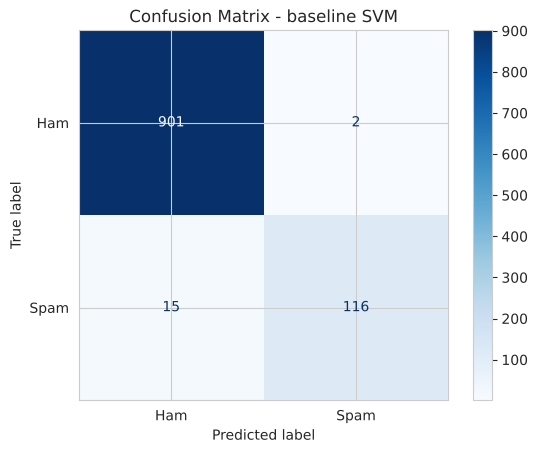

Ham wrongly flagged as spam (false positives): 2
Spam missed (false negatives): 15


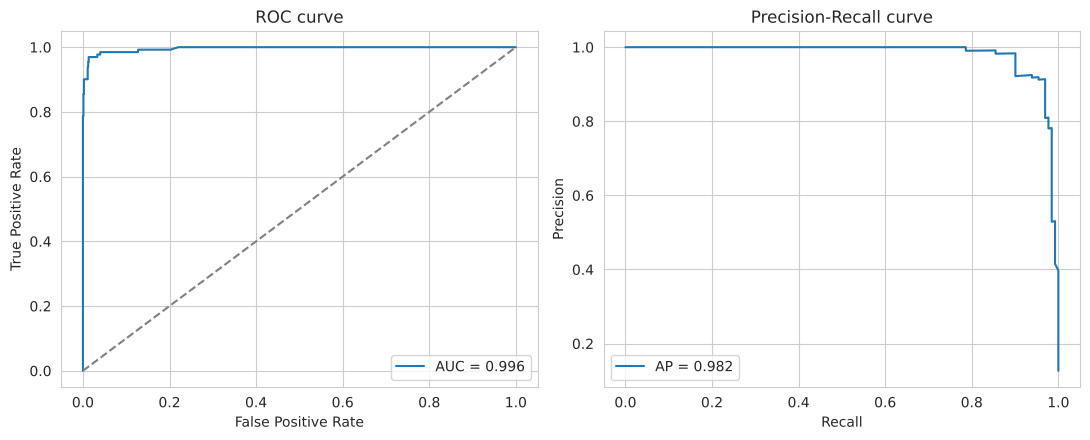

In [11]:
cm = confusion_matrix(y_test, pred)
ConfusionMatrixDisplay(cm, display_labels=["Ham", "Spam"]).plot(cmap="Blues")
plt.title("Confusion Matrix - baseline SVM"); plt.savefig("images/confusion_matrix_baseline.png", dpi=130); plt.show()
print("Ham wrongly flagged as spam (false positives):", cm[0, 1])
print("Spam missed (false negatives):", cm[1, 0])

scores = pipeline.decision_function(X_test)      # LinearSVC has no predict_proba; use decision scores
fpr, tpr, _ = roc_curve(y_test, scores); roc_auc = auc(fpr, tpr)
prec, rec, _ = precision_recall_curve(y_test, scores); ap = average_precision_score(y_test, scores)

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ax[0].plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}"); ax[0].plot([0, 1], [0, 1], "--", color="gray")
ax[0].set(xlabel="False Positive Rate", ylabel="True Positive Rate", title="ROC curve"); ax[0].legend()
ax[1].plot(rec, prec, label=f"AP = {ap:.3f}")
ax[1].set(xlabel="Recall", ylabel="Precision", title="Precision-Recall curve"); ax[1].legend()
plt.tight_layout(); plt.savefig("images/roc_pr_baseline.png", dpi=130); plt.show()

**Why add a Precision-Recall curve?** With imbalanced data the ROC curve looks great almost always. The PR curve is stricter because it only looks at the spam class.

## 9. Model comparison: why SVM?

,Model,Accuracy,Precision,Recall,F1
0,SVM (LinearSVC),0.9836,0.9831,0.8855,0.9317
1,Naive Bayes,0.9662,0.9898,0.7405,0.8472
2,Logistic Regression,0.9574,1.0000,0.6641,0.7982


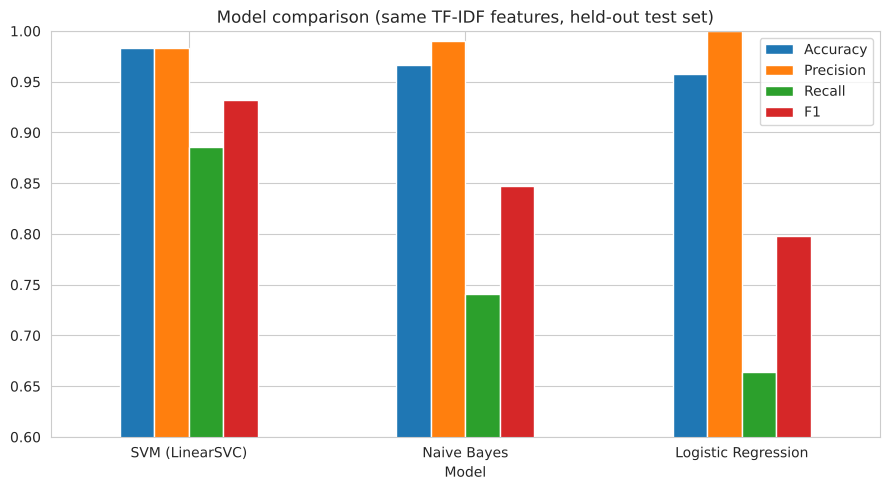

In [12]:
models = {"Naive Bayes": MultinomialNB(),
          "Logistic Regression": LogisticRegression(max_iter=1000),
          "SVM (LinearSVC)": LinearSVC()}
rows = []
for name, clf in models.items():
    p = Pipeline([("tfidf", TfidfVectorizer(max_features=5000, ngram_range=(1, 2))), ("clf", clf)])
    p.fit(X_train, y_train)
    rows.append(report(name, y_test, p.predict(X_test)))
results_df = pd.DataFrame(rows).sort_values("F1", ascending=False).reset_index(drop=True)
display(results_df.round(4))

results_df.set_index("Model")[["Accuracy", "Precision", "Recall", "F1"]].plot(kind="bar", figsize=(9, 5), ylim=(0.6, 1.0))
plt.title("Model comparison (same TF-IDF features, held-out test set)"); plt.xticks(rotation=0); plt.tight_layout()
plt.savefig("images/model_comparison.png", dpi=130); plt.show()

**Take-away:** all three have high accuracy, but SVM has the best **recall/F1** (it misses the least spam). Logistic Regression and Naive Bayes are very careful (high precision) but miss a lot of spam. SVMs work well on text because TF-IDF data has thousands of dimensions and SVM finds a wide-margin boundary in high dimensions.

## 10. Hyperparameter tuning (baseline)
`C` controls how strict the SVM is about getting every training point right (large C = strict, risk of over-fitting; small C = relaxed). `GridSearchCV` tries each value with 5-fold cross-validation on the **training** set only. We score on **F1** (not accuracy), because F1 respects the minority spam class.

In [13]:
param_grid = {"svm__C": [0.1, 0.5, 1, 2, 5, 10]}
grid = GridSearchCV(pipeline, param_grid, cv=5, scoring="f1", n_jobs=-1)
grid.fit(X_train, y_train)
print("Best parameters:", grid.best_params_)
print("Best CV F1     :", round(grid.best_score_, 4))

baseline_model = grid.best_estimator_
baseline_pred = baseline_model.predict(X_test)
print("\nTest set ->", {k: round(v, 4) for k, v in report("baseline", y_test, baseline_pred).items() if k != "Model"})

Best parameters: {'svm__C': 5}
Best CV F1     : 0.9132

Test set -> {'Accuracy': 0.9797, 'Precision': 0.9435, 'Recall': 0.8931, 'F1': 0.9176}


## 11. NEW - Better features: character + word n-grams on the raw text
**Idea:** our cleaning throws away information that actually signals spam - numbers (`150p`, `£1000`), symbols, capital letters, odd spellings (`txt`, `fr33`). Instead of only whole words, we let TF-IDF also look at **character n-grams** (pieces of 2-5 letters, e.g. `"£10"`, `"win "`, `"txt "`) on the **original** text. Spammers' tricks like *"FREE!!!"* or *"cl@im"* still share pieces with the normal spelling.

Because one train/test split is noisy (there are only ~130 spam messages in the test set), we compare approaches with **repeated 5-fold cross-validation** (5 folds x 3 repeats = 15 scores each).

,Approach,Accuracy,Precision,Recall,F1,F1 std
0,"A. Baseline: cleaned text, word 1-2 grams",0.9814,0.9761,0.8744,0.9223,0.0140
1,"B. Raw text, character 2-5 grams",0.9901,0.9952,0.9265,0.9594,0.0101
2,C. Char grams + handcrafted features,0.9890,0.9808,0.9316,0.9554,0.0135
3,"D. Raw text, char grams + word grams (combined)",0.9912,0.9936,0.9367,0.9642,0.0096


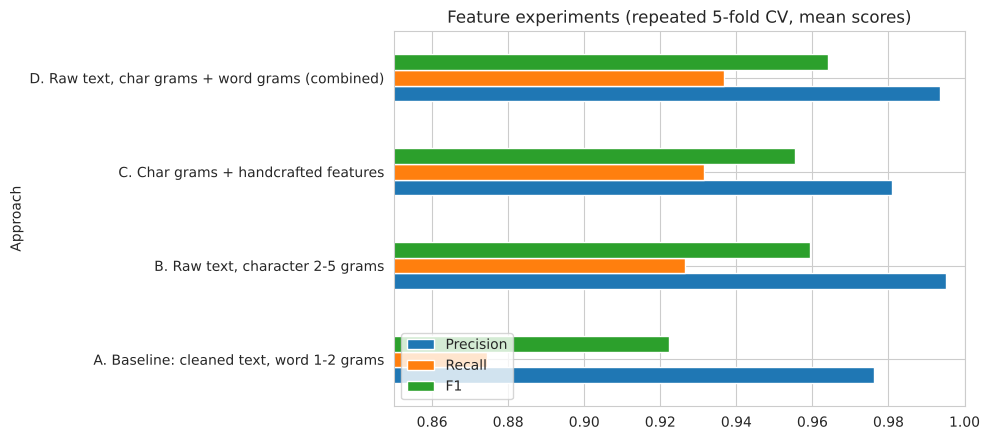

In [14]:
def word_tfidf():  return TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
def char_tfidf():  return TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True)
def word_raw():    return TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)

# a "negative result" experiment: hand-made features (length, digits, capitals, currency, links, '!')
def handcrafted(s):
    s = pd.Series(s); n = s.str.len().clip(lower=1)
    return csr_matrix(np.c_[np.log1p(n), s.str.count(r"\d") / n, s.str.count(r"[A-Z]") / n,
                            s.str.contains(r"[£$€]").astype(int),
                            s.str.contains(r"http|www|\.com", case=False).astype(int),
                            s.str.count("!")])
hand = lambda: Pipeline([("f", FunctionTransformer(handcrafted)), ("s", StandardScaler(with_mean=False))])

candidates = {
    "A. Baseline: cleaned text, word 1-2 grams":        (df["clean_message"], Pipeline([("t", word_tfidf()), ("c", LinearSVC())])),
    "B. Raw text, character 2-5 grams":                  (df["message"],       Pipeline([("t", char_tfidf()), ("c", LinearSVC())])),
    "C. Char grams + handcrafted features":              (df["message"],       Pipeline([("u", FeatureUnion([("t", char_tfidf()), ("f", hand())])), ("c", LinearSVC())])),
    "D. Raw text, char grams + word grams (combined)":   (df["message"],       Pipeline([("u", FeatureUnion([("t", char_tfidf()), ("w", word_raw())])), ("c", LinearSVC())])),
}
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
rows = []
for name, (X, p) in candidates.items():
    r = cross_validate(p, X, df["label"], cv=cv, scoring=["accuracy", "precision", "recall", "f1"], n_jobs=-1)
    rows.append({"Approach": name, "Accuracy": r["test_accuracy"].mean(), "Precision": r["test_precision"].mean(),
                 "Recall": r["test_recall"].mean(), "F1": r["test_f1"].mean(), "F1 std": r["test_f1"].std()})
feat_df = pd.DataFrame(rows)
display(feat_df.round(4))

ax = feat_df.set_index("Approach")[["Precision", "Recall", "F1"]].plot(kind="barh", figsize=(10, 4.5), xlim=(0.85, 1.0))
plt.title("Feature experiments (repeated 5-fold CV, mean scores)"); plt.legend(loc="lower left"); plt.tight_layout()
plt.savefig("images/feature_experiments.png", dpi=130); plt.show()

**Results:**
* **B and D clearly beat the baseline** - mainly because **recall goes up** (we catch more spam) while precision stays about the same.
* **C (handcrafted features) did *not* help** - the character n-grams already capture most of what "has a currency symbol / many digits / many capitals" would tell us. Reporting an idea that didn't work is a normal and honest part of ML experiments.
* We pick **D** as our improved model (best F1 in cross-validation).

### Tune the improved model and test it once on the held-out test set

Best parameters: {'svm__C': 5} | Best CV F1: 0.9654


,Accuracy,Precision,Recall,F1
Model,,,,
Baseline SVM (tuned),0.9797,0.9435,0.8931,0.9176
"Improved SVM (char+word, tuned)",0.9913,1.0000,0.9313,0.9644


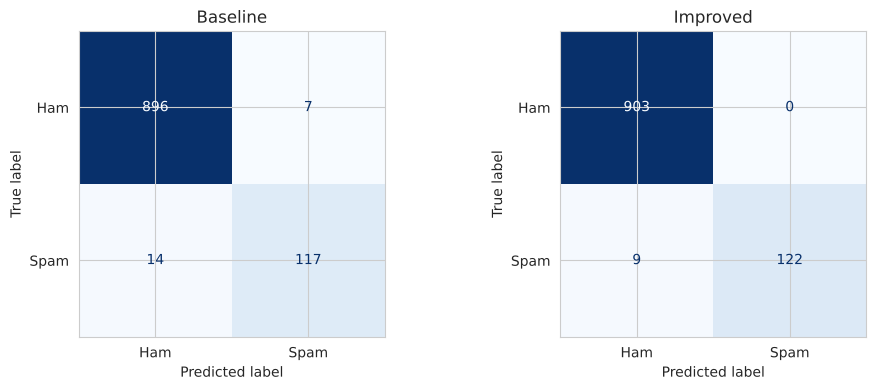

In [15]:
improved = Pipeline([("u", FeatureUnion([("t", char_tfidf()), ("w", word_raw())])), ("svm", LinearSVC())])
grid2 = GridSearchCV(improved, {"svm__C": [0.1, 0.5, 1, 2, 5]}, cv=5, scoring="f1", n_jobs=-1)
grid2.fit(Xr_train, y_train)
print("Best parameters:", grid2.best_params_, "| Best CV F1:", round(grid2.best_score_, 4))

best_model = grid2.best_estimator_
improved_pred = best_model.predict(Xr_test)

compare = pd.DataFrame([report("Baseline SVM (tuned)", y_test, baseline_pred),
                        report("Improved SVM (char+word, tuned)", y_test, improved_pred)]).set_index("Model")
display(compare.round(4))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, (t, p_) in zip(ax, [("Baseline", baseline_pred), ("Improved", improved_pred)]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, p_), display_labels=["Ham", "Spam"]).plot(cmap="Blues", ax=a, colorbar=False)
    a.set_title(t)
plt.tight_layout(); plt.savefig("images/confusion_matrix_compare.png", dpi=130); plt.show()

Note: the test set is small (~130 spam messages), so a difference of 1-2 messages is not significant on its own. The cross-validation table above (15 scores per approach) is the stronger evidence for the improvement.

## 12. Cross-validation of the final model
Same as in the lab notebook: 5-fold stratified CV on the whole (de-duplicated) dataset, now with F1 as well as accuracy.

In [16]:
for name, mdl, X in [("Baseline", baseline_model, df["clean_message"]), ("Improved", best_model, df["message"])]:
    acc = cross_val_score(mdl, X, df["label"], cv=5, scoring="accuracy")
    f1s = cross_val_score(mdl, X, df["label"], cv=5, scoring="f1")
    print(f"{name:9s} accuracy {acc.mean():.4f} (+/- {acc.std():.4f}) | F1 {f1s.mean():.4f} (+/- {f1s.std():.4f})")

Baseline  accuracy 0.9768 (+/- 0.0018) | F1 0.9032 (+/- 0.0076)


Improved  accuracy 0.9905 (+/- 0.0034) | F1 0.9610 (+/- 0.0147)


## 13. NEW - Threshold tuning: choosing how cautious the filter is
The SVM gives every message a **score**; above 0 means "spam". But 0 is just a default. In a real phone, wrongly hiding a *real* message (false positive) is worse than letting one spam through. So we can raise the threshold to get **higher precision** (at the cost of some recall).

To avoid cheating, the threshold is chosen using **cross-validated scores on the training set only**; the test set is used once at the end.

Chosen threshold: 0.111 (default is 0.0)


,Accuracy,Precision,Recall,F1
Model,,,,
Default threshold (0.0),0.9913,1.0,0.9313,0.9644
Strict threshold (0.11),0.9894,1.0,0.9160,0.9562


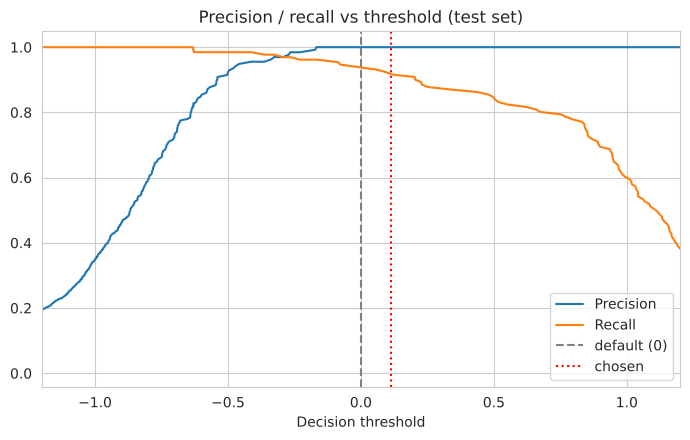

In [17]:
train_scores = cross_val_predict(best_model, Xr_train, y_train, cv=5, method="decision_function")
p_, r_, thr = precision_recall_curve(y_train, train_scores)

# lowest threshold that gives >= 99.5% precision on the training folds
ok = np.where(p_[:-1] >= 0.995)[0]
chosen = thr[ok[0]] if len(ok) else 0.0
print("Chosen threshold:", round(float(chosen), 3), "(default is 0.0)")

test_scores = best_model.decision_function(Xr_test)
rows = []
for name, t in [("Default threshold (0.0)", 0.0), (f"Strict threshold ({chosen:.2f})", chosen)]:
    rows.append(report(name, y_test, (test_scores > t).astype(int)))
thr_df = pd.DataFrame(rows).set_index("Model"); display(thr_df.round(4))

plt.figure(figsize=(7, 4.5))
tp, tr, tt = precision_recall_curve(y_test, test_scores)
plt.plot(tt, tp[:-1], label="Precision"); plt.plot(tt, tr[:-1], label="Recall")
plt.axvline(0, color="gray", ls="--", label="default (0)"); plt.axvline(chosen, color="red", ls=":", label="chosen")
plt.xlabel("Decision threshold"); plt.title("Precision / recall vs threshold (test set)"); plt.legend(); plt.xlim(-1.2, 1.2)
plt.tight_layout(); plt.savefig("images/threshold_tradeoff.png", dpi=130); plt.show()

**Take-away:** moving the threshold slides us along the precision-recall trade-off. On this test set the default threshold already produces **no false alarms**, so a stricter threshold can only lose recall here - it would pay off on data where real messages get flagged. Which point is 'best' depends on the cost of each kind of mistake, which is a business decision, not just a maths one.

## 14. NEW - Which words make a message spam?
A linear SVM is easy to explain: every feature gets a **weight**. Big positive weight = pushes towards spam; big negative = pushes towards ham. (We look at the *word* features only, because character pieces are hard to read.)

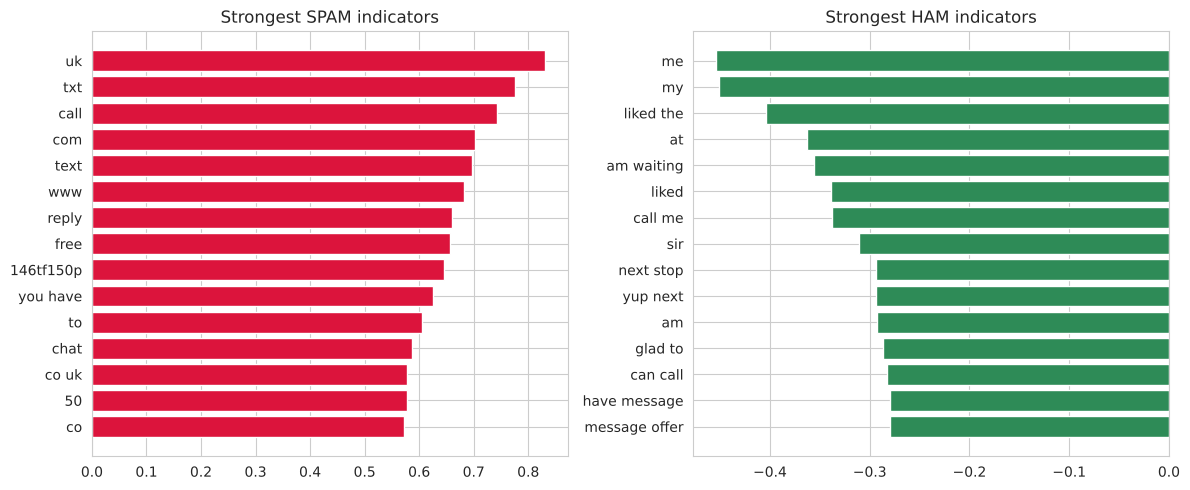

Top spam words: uk, txt, call, com, text, www, reply, free, 146tf150p, you have
Top ham words : me, my, liked the, at, am waiting, liked, call me, sir, next stop, yup next


In [18]:
names = best_model.named_steps["u"].get_feature_names_out()
w = best_model.named_steps["svm"].coef_[0]
is_word = np.array([n.startswith("w__") for n in names])
words = np.array([n[3:] for n in names])[is_word]; ww = w[is_word]
order = np.argsort(ww)
top_spam, top_ham = order[-15:][::-1], order[:15]

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].barh(words[top_spam][::-1], ww[top_spam][::-1], color="crimson"); ax[0].set_title("Strongest SPAM indicators")
ax[1].barh(words[top_ham][::-1], ww[top_ham][::-1], color="seagreen"); ax[1].set_title("Strongest HAM indicators")
plt.tight_layout(); plt.savefig("images/top_words.png", dpi=130); plt.show()
print("Top spam words:", ", ".join(words[top_spam][:10]))
print("Top ham words :", ", ".join(words[top_ham][:10]))

## 15. Error analysis - where does the model still fail?
We print the **original** messages (not the cleaned ones) so we can actually read them.

In [19]:
res = test_df[["message", "label"]].copy()
res["predicted"] = improved_pred; res["score"] = best_model.decision_function(Xr_test)
wrong = res[res.label != res.predicted]
print(f"Misclassified: {len(wrong)} of {len(res)}")

fp = wrong[wrong.label == 0]; fn = wrong[wrong.label == 1].sort_values("score", ascending=False)
print(f"\nFalse positives (real message flagged as spam): {len(fp)}")
for m in fp.message.head(5): print(" -", m[:200])
print(f"\nFalse negatives (spam that slipped through): {len(fn)}")
for m in fn.message.head(6): print(" -", m[:200])

Misclassified: 9 of 1034

False positives (real message flagged as spam): 0

False negatives (spam that slipped through): 9
 - Check Out Choose Your Babe Videos @ sms.shsex.netUN fgkslpoPW fgkslpo
 - Missed call alert. These numbers called but left no message. 07008009200
 - Xmas & New Years Eve tickets are now on sale from the club, during the day from 10am till 8pm, and on Thurs, Fri & Sat night this week. They're selling fast!
 - Babe: U want me dont u baby! Im nasty and have a thing 4 filthyguys. Fancy a rude time with a sexy bitch. How about we go slo n hard! Txt XXX SLO(4msgs)
 - Burger King - Wanna play footy at a top stadium? Get 2 Burger King before 1st Sept and go Large or Super with Coca-Cola and walk out a winner
 - ringtoneking 84484


**Typical pattern:** the missed spam is often *very short or promotional text that looks like normal chat* (e.g. just a ringtone code, a "missed call" alert, a restaurant/club promotion) with few classic trigger words. That is a real limitation of bag-of-words models - they don't understand meaning. A next step would be a transformer model (e.g. DistilBERT).

## 16. Save the model and use it

In [20]:
import joblib
joblib.dump(best_model, "models/sms_spam_svm_model.pkl")
print("Saved models/sms_spam_svm_model.pkl")
# model = joblib.load("models/sms_spam_svm_model.pkl")   # load it later without retraining

def predict_sms(text, threshold=0.0):
    """Return ('Spam' or 'Ham', score). Score > threshold means spam; bigger = more confident."""
    score = float(best_model.decision_function([text])[0])
    return ("Spam" if score > threshold else "Ham"), round(score, 3)

tests = ["Congratulations! You have won a free iPhone. Click here now.",
         "Hi, are we meeting tomorrow at 3 PM?",
         "URGENT! Your mobile number has won a 1000 GBP cash prize. Call 09061701461 to claim.",
         "Can you send me the notes from today's lab? Thanks!",
         "FREE entry in 2 a weekly comp to win FA Cup tickets. Text FA to 87121 to receive entry"]
for t in tests:
    print(predict_sms(t), "<-", t[:70])

Saved models/sms_spam_svm_model.pkl
('Spam', 0.216) <- Congratulations! You have won a free iPhone. Click here now.
('Ham', -1.28) <- Hi, are we meeting tomorrow at 3 PM?
('Spam', 1.681) <- URGENT! Your mobile number has won a 1000 GBP cash prize. Call 0906170
('Ham', -1.026) <- Can you send me the notes from today's lab? Thanks!
('Spam', 0.564) <- FREE entry in 2 a weekly comp to win FA Cup tickets. Text FA to 87121 


## 17. Final summary

In [21]:
final = pd.DataFrame([report("Baseline SVM (tuned)", y_test, baseline_pred),
                      report("Improved SVM (char+word)", y_test, improved_pred),
                      report("Improved + strict threshold", y_test, (test_scores > chosen).astype(int))]).set_index("Model")
display(final.round(4))
final.round(4).to_csv("images/final_results.csv"); feat_df.round(4).to_csv("images/feature_experiments.csv", index=False)

,Accuracy,Precision,Recall,F1
Model,,,,
Baseline SVM (tuned),0.9797,0.9435,0.8931,0.9176
Improved SVM (char+word),0.9913,1.0000,0.9313,0.9644
Improved + strict threshold,0.9894,1.0000,0.9160,0.9562


### Conclusion
* A TF-IDF + linear SVM is already a strong spam detector (~98% accuracy).
* Looking at the **original text with character n-grams** gives the biggest real improvement, mainly by catching more spam.
* Extra handcrafted features did not help - worth knowing and reporting.
* Threshold tuning shows the precision/recall trade-off; on this test set the default threshold already had zero false alarms, so no change was needed.
* Limitations: small dataset (British/Singaporean-style English SMS from ~2005), bag-of-words ignores meaning, and the test set contains only ~130 spam messages.